In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence  import variance_inflation_factor
from sklearn.preprocessing import LabelEncoder

In [3]:
a_ev = pd.read_csv('/Users/bennysun/Downloads/athlete_events.csv')

In [4]:
a_ev.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [26]:
l = LabelEncoder()
a_ev['Medal_Labels'] = l.fit_transform(a_ev['Medal'])
df = a_ev[["Age", 'Height', 'Weight', 'Medal_Labels']]
metadata = df.dropna(subset=["Age", "Height", "Weight"])
metadata = metadata.drop("Medal_Labels", axis = 1)
X = sm.add_constant(metadata)
vif_a_ev = pd.DataFrame()
vif_a_ev["Metadata"] = X.columns
vif_a_ev["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_a_ev)

  Metadata         VIF
0    const  487.766519
1      Age    1.049306
2   Height    2.742008
3   Weight    2.813460


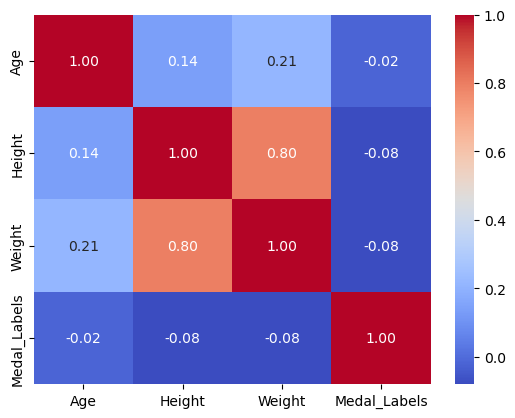

In [27]:
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.show()


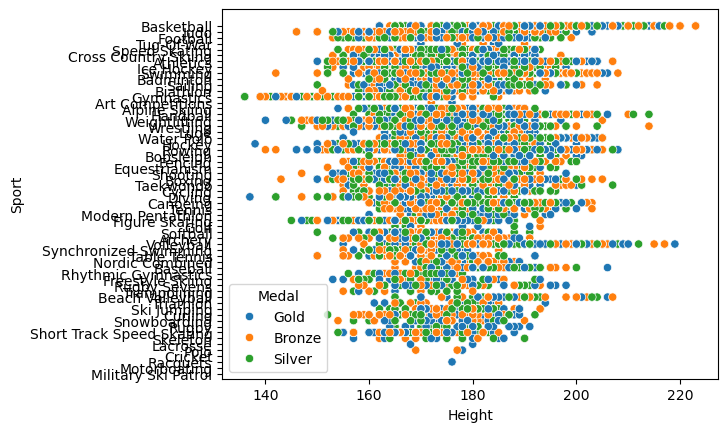